# Dimensionality Reduction
Sometimes the "actual" dimensions of the data might not correspond to the dimensions we have. 
 
**PCA** finds the directions in your data where the points vary the most. 

The steps are the following: 

**1)** Find the direction with maximum variance → first principal component 

**2)** Project the data onto that direction 

**3)** Remove that direction from the data (the explained part) 

**4)** Repeat to find the next directions 

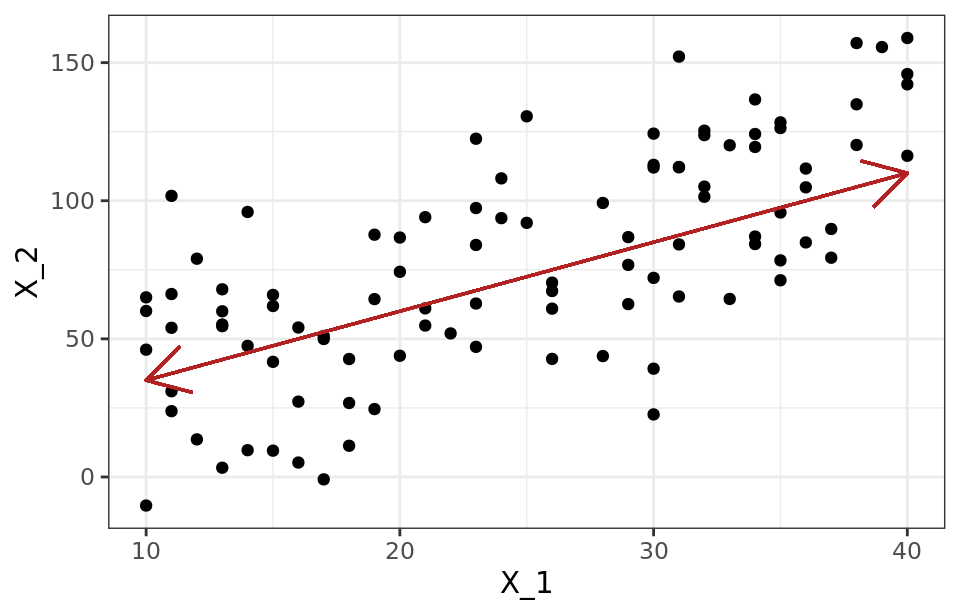
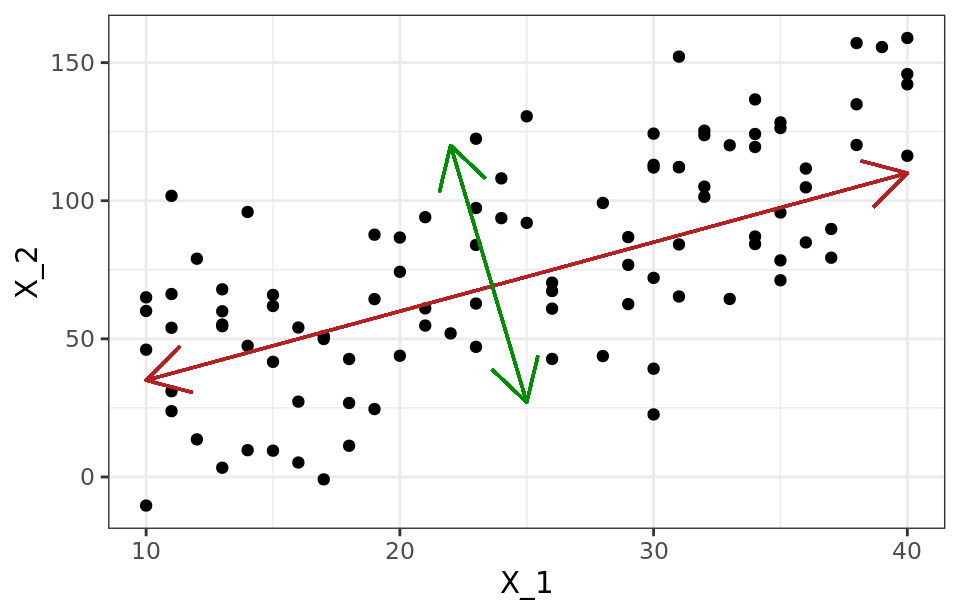

**Before using PCA** 

**-** Scale Features before applying PCA

**-** Accuracy might drop


## Steps to build the model

**1.Standardising the data :** 
We´ll need to translate the data so that each dimensions has mean 0:

In [1]:
from linear_algebra import subtract,vector_mean,Vector
from typing import List, Dict

def de_mean(data: List[Vector]) -> List[Vector]:
    """Recenters the data to have mean 0 in every dimension"""
    mean = vector_mean(data)
    return [subtract(vector, mean) for vector in data]

**2.Find de direction that captures the highest variance:** 
Given a direction d ( a vector of magnitude 1), each row x in the matrix etends dot(x,d) in the d direction. And every non zero vector w determines a direction if we rescale it to have magnitude 1.
first principal component.

In [2]:
from linear_algebra import magnitude

def direction(w: Vector) -> Vector:
    mag = magnitude(w)
    return [w_i / mag for w_i in w] # Rescale the vector so it has magnitude 1 (We only care about the direction, not the magnitude)

**3.Find the projection of the vector x onto directional vector w:**  
Given a non zero vector w, we can compute the variance of the dataset in the direction determined by w

In [3]:
from linear_algebra import dot

def directional_variance(data: List[Vector], w: Vector) -> float:
    """
    Returns the variance of x in the direction of w
    """
    w_dir = direction(w) # rescale to get a vector of magnitude 1
    return sum(dot(v, w_dir) ** 2 for v in data) #total variance of the entire dataset along w direction

**4.Find the gradient descent** 
We need to find the direction vector that maximizes this variance. To do so, let´s find the derivate of the variance with respect to w

In [4]:
def directional_variance_gradient(data: List[Vector], w: Vector) -> Vector:
    """
    The gradient of directional variance with respect to w
    """
    w_dir = direction(w)
    return [sum(2 * dot(v, w_dir) * v[i] for v in data)
            for i in range(len(w))] # The result is a list with the gradient for each element of the directional vector

**4.Itirate until finding convergence** 
Let´s use the gradient descent to find the directional vector w that maximizes the variance. This vector would be the First Principal Component

In [5]:
from gradient_descent import gradient_step

def first_principal_component(data: List[Vector],
                              n: int = 100,
                              step_size: float = 0.1) -> Vector:
    # Start with a random guess
    guess = [1.0 for _ in data[0]]

    with tqdm.trange(n) as t:
        for _ in t:
            dv = directional_variance(data, guess)
            gradient = directional_variance_gradient(data, guess)
            guess = gradient_step(guess, gradient, step_size)
            t.set_description(f"dv: {dv:.3f}")

    return direction(guess)

**4.Project the data onto the directional vector** 


In [6]:
from linear_algebra import scalar_multiply

def project(v: Vector, w: Vector) -> Vector:
    """return the projection of v onto the direction w"""
    projection_length = dot(v, w) #scalar (number) length of the projection if w is a unit vector.
    return scalar_multiply(projection_length, w) # The result is a new vector with the
                                                 #projection vector or data onto the directional vector ( we need to do this for each data in the dataset)


**5. Remove First component projection from the data**
If we need to find further components, we first remove the projections from the data because this new component must capture new variance, not variance already explained by w₁. The result is the part of v that is not aligned with w.

In [7]:
from linear_algebra import subtract

def remove_projection_from_vector(v: Vector, w: Vector) -> Vector:
    """projects v onto w and subtracts the result from v"""
    return subtract(v, project(v, w))# Removes the part of v that lies in the direction w


Let´s do the same for the whole dataset:

In [8]:
def remove_projection(data: List[Vector], w: Vector) -> List[Vector]:
    return [remove_projection_from_vector(v, w) for v in data]

**6.Iterate to find the number of components you need**
We can find the next principal component, that would be the direction of maximum remaining variance, by repeating the process on the result of the remove-projection

In [9]:
def pca(data: List[Vector], num_components: int) -> List[Vector]:
    components: List[Vector] = []
    for _ in range(num_components):
        component = first_principal_component(data) # Find the direction vector that explains the highest variance
        components.append(component) # Save the vestor in a list of components
        data = remove_projection(data, component) # Remove the projection of the data onto this directional vector

    return components

**7.re-express your data in terms of these new axes**
We need to find the vector of projections onto the principal components, this to represent the data in reduced PCA space for analysis or regression

In [10]:
def transform_vector(v: Vector, components: List[Vector]) -> Vector:
    return [dot(v, w) for w in components]

Let´s do this for the whole dataset:

In [11]:
def transform(data: List[Vector], components: List[Vector]) -> List[Vector]:
    return [transform_vector(v, components) for v in data]

## PCA using sklearn
Let´s see an example when trying to predict a number based on the pixels of the image: 

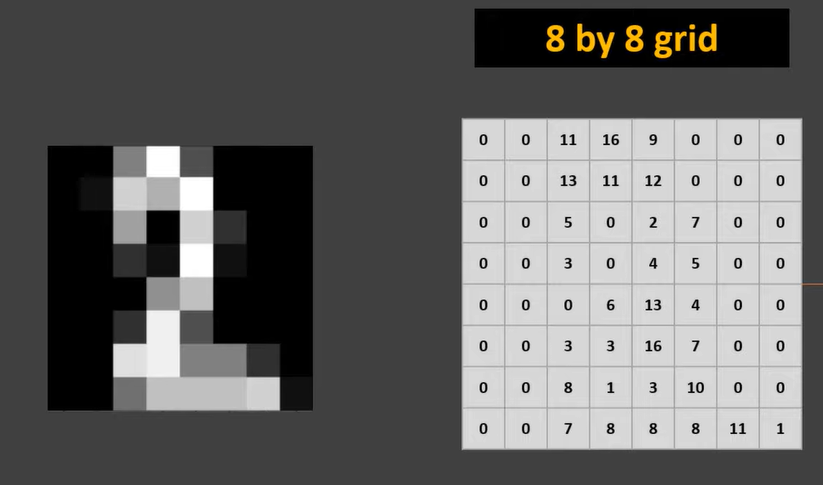
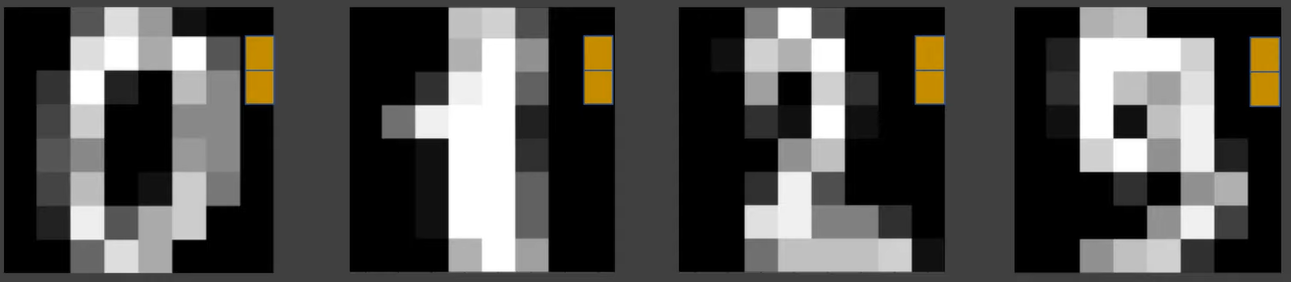


In [12]:
from sklearn.datasets import load_digits
import pandas as pd

dataset = load_digits()
dataset.keys()

dict_keys(['data', 'target', 'frame', 'feature_names', 'target_names', 'images', 'DESCR'])

In [13]:
dataset.data.shape

(1797, 64)

In [14]:
dataset.data[0]

array([ 0.,  0.,  5., 13.,  9.,  1.,  0.,  0.,  0.,  0., 13., 15., 10.,
       15.,  5.,  0.,  0.,  3., 15.,  2.,  0., 11.,  8.,  0.,  0.,  4.,
       12.,  0.,  0.,  8.,  8.,  0.,  0.,  5.,  8.,  0.,  0.,  9.,  8.,
        0.,  0.,  4., 11.,  0.,  1., 12.,  7.,  0.,  0.,  2., 14.,  5.,
       10., 12.,  0.,  0.,  0.,  0.,  6., 13., 10.,  0.,  0.,  0.])

In [15]:
dataset.data[0].reshape(8,8) # For visualization

array([[ 0.,  0.,  5., 13.,  9.,  1.,  0.,  0.],
       [ 0.,  0., 13., 15., 10., 15.,  5.,  0.],
       [ 0.,  3., 15.,  2.,  0., 11.,  8.,  0.],
       [ 0.,  4., 12.,  0.,  0.,  8.,  8.,  0.],
       [ 0.,  5.,  8.,  0.,  0.,  9.,  8.,  0.],
       [ 0.,  4., 11.,  0.,  1., 12.,  7.,  0.],
       [ 0.,  2., 14.,  5., 10., 12.,  0.,  0.],
       [ 0.,  0.,  6., 13., 10.,  0.,  0.,  0.]])

<Figure size 432x288 with 0 Axes>

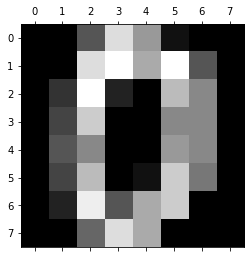

In [16]:
from matplotlib import pyplot as plt
%matplotlib inline
plt.gray()
plt.matshow(dataset.data[0].reshape(8,8))

In [17]:
dataset.target[:5]

array([0, 1, 2, 3, 4])

In [18]:
df = pd.DataFrame(dataset.data, columns=dataset.feature_names)
df.head()

,pixel_0_0,pixel_0_1,pixel_0_2,pixel_0_3,pixel_0_4,pixel_0_5,pixel_0_6,pixel_0_7,pixel_1_0,pixel_1_1,...,pixel_6_6,pixel_6_7,pixel_7_0,pixel_7_1,pixel_7_2,pixel_7_3,pixel_7_4,pixel_7_5,pixel_7_6,pixel_7_7
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,5.0,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,9.0,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0


In [19]:
dataset.target

array([0, 1, 2, ..., 8, 9, 8])

In [20]:
X = df
y = dataset.target

Let´s standardize using the functions from sklearn:

In [21]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled

array([[ 0.        , -0.33501649, -0.04308102, ..., -1.14664746,
        -0.5056698 , -0.19600752],
       [ 0.        , -0.33501649, -1.09493684, ...,  0.54856067,
        -0.5056698 , -0.19600752],
       [ 0.        , -0.33501649, -1.09493684, ...,  1.56568555,
         1.6951369 , -0.19600752],
       ...,
       [ 0.        , -0.33501649, -0.88456568, ..., -0.12952258,
        -0.5056698 , -0.19600752],
       [ 0.        , -0.33501649, -0.67419451, ...,  0.8876023 ,
        -0.5056698 , -0.19600752],
       [ 0.        , -0.33501649,  1.00877481, ...,  0.8876023 ,
        -0.26113572, -0.19600752]])

Let´s divide the sample in 80%-20%

In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=30)

In [23]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train, y_train)
model.score(X_test, y_test)

0.9722222222222222

## Use PCA to reduce dimensions

In [24]:
from sklearn.decomposition import PCA

pca = PCA(0.95) # Create new features keeping the 95% of the variance of the data
X_pca = pca.fit_transform(X)
X_pca.shape

(1797, 29)

The number of features changed from **64** to **29**. It doesn´t remove features but create new ones with the variance of the original ones.

In [25]:
pca.explained_variance_ratio_

array([0.14890594, 0.13618771, 0.11794594, 0.08409979, 0.05782415,
       0.0491691 , 0.04315987, 0.03661373, 0.03353248, 0.03078806,
       0.02372341, 0.02272697, 0.01821863, 0.01773855, 0.01467101,
       0.01409716, 0.01318589, 0.01248138, 0.01017718, 0.00905617,
       0.00889538, 0.00797123, 0.00767493, 0.00722904, 0.00695889,
       0.00596081, 0.00575615, 0.00515158, 0.0048954 ])

**The explained variance ratio** indicates how much of the variance is captured by each component

In [26]:
pca.n_components_


29

In [27]:
X_train_pca, X_test_pca, y_train, y_test = train_test_split(X_pca, y, test_size=0.2, random_state=30)

In [28]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train_pca, y_train)
model.score(X_test_pca, y_test)

0.9694444444444444

By reducing the original components, it´s also redued the accuracy from **97,2%** to **96,9%**

In [29]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
X_pca.shape
X_pca

array([[ -1.25946897,  21.27488944],
       [  7.95761316, -20.76870317],
       [  6.99192531,  -9.95599185],
       ...,
       [ 10.80127937,  -6.96024271],
       [ -4.8720909 ,  12.42393389],
       [ -0.34439288,   6.36555645]])

In [30]:
pca.explained_variance_ratio_

array([0.14890594, 0.13618771])

With 2 components, we are only capturing **28%** of the variance of the original data

In [31]:
X_train_pca, X_test_pca, y_train, y_test = train_test_split(X_pca, y, test_size=0.2, random_state=30)

model = LogisticRegression(max_iter=1000)
model.fit(X_train_pca, y_train)
model.score(X_test_pca, y_test)

0.6083333333333333

With only 2 components, the accuracy of the model dropped to **60%**

### Classifying Flowers

The Iris Dataset is a well known database in the pattern recognition literature. The data set contains 3 classes of 50 instances each, where each class refers to a type of iris plant.

Four features are given:
1. sepal length in cm 
2. sepal width in cm 
3. petal length in cm 
4. petal width in cm 

We will explore this dataset next.

In [32]:
from sklearn import datasets

iris = datasets.load_iris()
X = iris.data
y = iris.target

print(X[:10])
print(y[:10])

list(iris.target_names)

[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]
 [5.4 3.9 1.7 0.4]
 [4.6 3.4 1.4 0.3]
 [5.  3.4 1.5 0.2]
 [4.4 2.9 1.4 0.2]
 [4.9 3.1 1.5 0.1]]
[0 0 0 0 0 0 0 0 0 0]


['setosa', 'versicolor', 'virginica']

Your job is to find the create a model that predicts the target variable and them reduce the features to 3 and see how much of the accuracy changes with the reduction.
